In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [16]:
!pip install optuna

In [17]:
!pip install catboost

In [18]:
from catboost import CatBoostClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
import optuna

In [19]:
train = pd.read_csv('train_fe.csv')
test = pd.read_csv('test_fe.csv')

## New advanced features

In [20]:
compound_max_life = train.groupby('Compound')['TyreLife'].max().reset_index()
compound_max_life.rename(columns={'TyreLife': 'Track_Compound_Max_Life'}, inplace=True)

train['is_train'] = 1
test['is_train'] = 0
df = pd.concat([train, test], ignore_index=True)

df = df.merge(compound_max_life, on='Compound', how='left')

df['orig_index'] = np.arange(len(df))

df = df.sort_values(by=['Race', 'Year', 'Driver', 'LapNumber'])
# Grid pressure
# tyre age difference from the average of the grid
df['Grid_Avg_TyreLife'] = df.groupby(['Race', 'Year', 'LapNumber'])['TyreLife'].transform('mean')
df['TyreLife_vs_Grid'] = df['TyreLife'] - df['Grid_Avg_TyreLife']

# Compound death
if 'Track_Compound_Max_Life' not in df.columns:
    df['Track_Compound_Max_Life'] = df.groupby(['Race', 'Year', 'Compound'])['TyreLife'].transform('max')
df['Normalized_TyreLife_Squared'] = (df['TyreLife'] / (df['Track_Compound_Max_Life'] + 1e-5)) ** 2

# Pace Drop and Position Loss
df['Panic_Indicator'] = df['LapTime_Delta'] * df['Position_Change']
df['Panic_Indicator'] = df['Panic_Indicator'].apply(lambda x: x if x > 0 else 0)

# Rolling features
df['Gap_To_Fastest_Rolling3'] = df.groupby(['Race', 'Year', 'Driver'])['Gap_To_Fastest'].transform(lambda x: x.rolling(3, min_periods=1).mean())
df['LapTime_Delta_Rolling3_Sum'] = df.groupby(['Race', 'Year', 'Driver'])['LapTime_Delta'].transform(lambda x: x.rolling(3, min_periods=1).sum())

df.drop(columns=['Grid_Avg_TyreLife', 'Track_Compound_Max_Life'], inplace=True, errors='ignore')

df = df.sort_values(by='orig_index').drop(columns=['orig_index'])

train_df = df[df['is_train'] == 1].drop(columns=['is_train'])
test_df = df[df['is_train'] == 0].drop(columns=['is_train', 'PitNextLap'])

In [21]:
X = train_df.drop(columns=['PitNextLap'])
y = train_df['PitNextLap']
X_test = test_df.copy()

cat_cols = ['Driver', 'Compound', 'Race']
for col in cat_cols:
    X[col] = X[col].astype(str)
    X_test[col] = X_test[col].astype(str)

In [22]:

def objective(trial):
    param = {
        'iterations': 1000,
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'depth': trial.suggest_int('depth', 4, 9),
        'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1e-3, 10.0, log=True),
        'random_strength': trial.suggest_float('random_strength', 1.0, 20.0),
        'bagging_temperature': trial.suggest_float('bagging_temperature', 0.0, 1.0),
        'auto_class_weights': 'Balanced',
        'random_seed': 42,
        'task_type': 'GPU',
        'verbose': 0
    }

    skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
    cv_scores = []

    for train_idx, val_idx in skf.split(X, y):
        X_tr, y_tr = X.iloc[train_idx], y.iloc[train_idx]
        X_va, y_va = X.iloc[val_idx], y.iloc[val_idx]

        model = CatBoostClassifier(**param)
        model.fit(X_tr, y_tr, eval_set=(X_va, y_va), cat_features=cat_cols, early_stopping_rounds=50, use_best_model=True)
        preds = model.predict_proba(X_va)[:, 1]
        cv_scores.append(roc_auc_score(y_va, preds))

    return np.mean(cv_scores)

study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=20)

print("\nBest params:", study.best_params)
print(f"Best OOF ROC AUC (3-fold): {study.best_value:.5f}")



[I 2026-11-05 20:46:36,175] A new study created in memory with name: no-name-5c5c53d4-3471-4297-ab15-161846088402
[I 2026-11-05 20:47:31,222] Trial 0 finished with value: 0.9423445160575522 and parameters: {'learning_rate': 0.03156001260720695, 'depth': 6, 'l2_leaf_reg': 0.01276946039407148, 'random_strength': 18.584593736843487, 'bagging_temperature': 0.39559328792094306}. Best is trial 0 with value: 0.9423445160575522.
[I 2026-11-05 20:48:39,367] Trial 1 finished with value: 0.9456606449462394 and parameters: {'learning_rate': 0.04975581225351043, 'depth': 7, 'l2_leaf_reg': 1.0158720688377825, 'random_strength': 10.589338283681727, 'bagging_temperature': 0.13803177718115212}. Best is trial 1 with value: 0.9456606449462394.
[I 2026-11-05 20:49:49,791] Trial 2 finished with value: 0.9446979581581574 and parameters: {'learning_rate': 0.03389876483170215, 'depth': 7, 'l2_leaf_reg': 0.8846832165905276, 'random_strength': 5.867688647110752, 'bagging_temperature': 0.139895319508068}. Best i


Best params: {'learning_rate': 0.08938714520150838, 'depth': 7, 'l2_leaf_reg': 6.586285111828744, 'random_strength': 18.17059189707539, 'bagging_temperature': 0.1147390657611596}
Best OOF ROC AUC (3-fold): 0.94650


In [23]:
final_params = {
    'iterations': 2000,
    'learning_rate': study.best_params['learning_rate'],
    'depth': study.best_params['depth'],
    'l2_leaf_reg': study.best_params['l2_leaf_reg'],
    'random_strength': study.best_params['random_strength'],
    'bagging_temperature': study.best_params['bagging_temperature'],
    'auto_class_weights': 'Balanced',
    'random_seed': 42,
    'task_type': 'GPU',
    'verbose': 250
}

oof_preds_cb = np.zeros(len(X))
test_preds_cb = np.zeros(len(X_test))
skf_final = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for fold, (train_idx, val_idx) in enumerate(skf_final.split(X, y)):
    X_tr, y_tr = X.iloc[train_idx], y.iloc[train_idx]
    X_va, y_va = X.iloc[val_idx], y.iloc[val_idx]

    model_cb = CatBoostClassifier(**final_params)
    model_cb.fit(X_tr, y_tr, eval_set=(X_va, y_va), cat_features=cat_cols, early_stopping_rounds=100, use_best_model=True)

    val_probs = model_cb.predict_proba(X_va)[:, 1]
    oof_preds_cb[val_idx] = val_probs
    test_preds_cb += model_cb.predict_proba(X_test)[:, 1] / skf_final.n_splits
    print(f"Fold {fold+1} ROC AUC: {roc_auc_score(y_va, val_probs):.5f}")

print(f"\nFinal ROC AUC: {roc_auc_score(y, oof_preds_cb):.5f}")

submission_cb = pd.read_csv('sample_submission.csv')
submission_cb['PitNextLap'] = test_preds_cb
submission_cb.to_csv('catboost_advanced_fe_submission.csv', index=False)

0:	learn: 0.6416685	test: 0.6414674	best: 0.6414674 (0)	total: 23.7ms	remaining: 47.4s
250:	learn: 0.2954480	test: 0.2977080	best: 0.2977080 (250)	total: 5.36s	remaining: 37.4s
500:	learn: 0.2762346	test: 0.2878910	best: 0.2878910 (500)	total: 11s	remaining: 32.8s
750:	learn: 0.2636937	test: 0.2849525	best: 0.2849525 (750)	total: 16.5s	remaining: 27.5s
1000:	learn: 0.2536777	test: 0.2837523	best: 0.2837281 (993)	total: 22s	remaining: 21.9s
1250:	learn: 0.2450807	test: 0.2832115	best: 0.2832037 (1249)	total: 27.4s	remaining: 16.4s
bestTest = 0.2831200133
bestIteration = 1358
Shrink model to first 1359 iterations.
Fold 1 ROC AUC: 0.94850
0:	learn: 0.6421923	test: 0.6420211	best: 0.6420211 (0)	total: 23.1ms	remaining: 46.2s
250:	learn: 0.2931196	test: 0.3029988	best: 0.3029988 (250)	total: 5.36s	remaining: 37.4s
500:	learn: 0.2740722	test: 0.2935998	best: 0.2935998 (500)	total: 10.8s	remaining: 32.4s
750:	learn: 0.2617220	test: 0.2909945	best: 0.2909938 (746)	total: 16.2s	remaining: 26.9s

/tmp/ipykernel_5576/2277555392.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=fi_cb_adv_df.head(20), x='Importance', y='Feature', palette='mako')


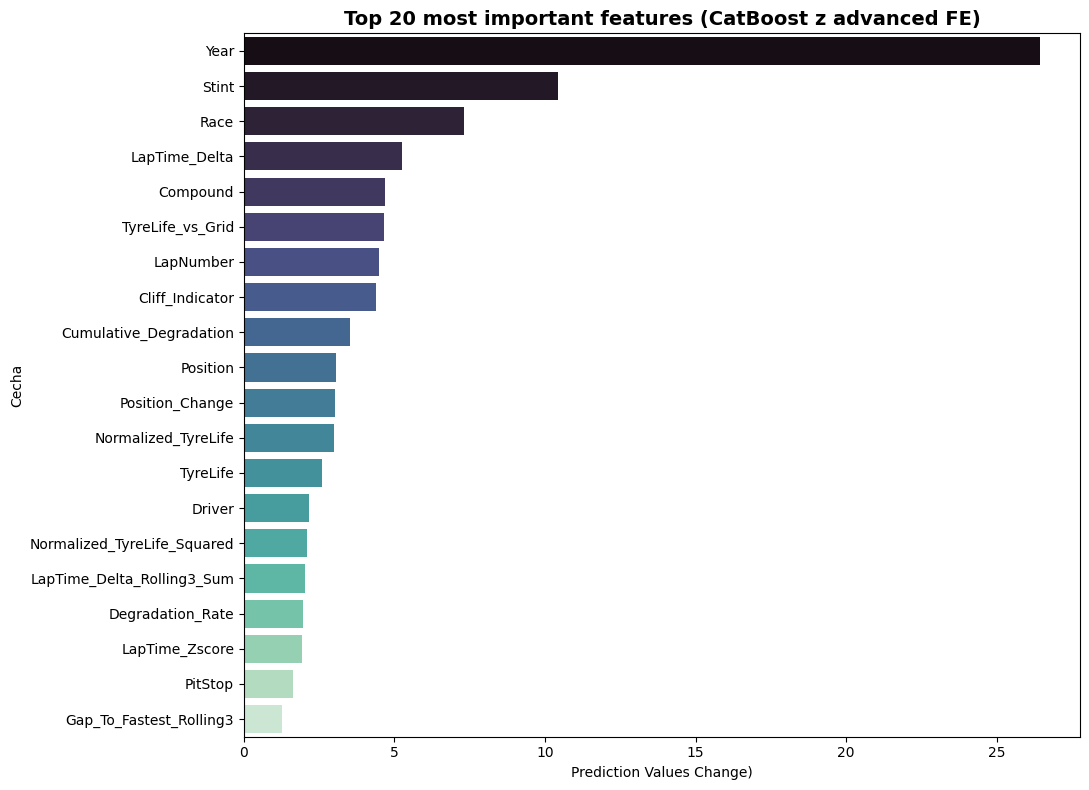

In [24]:
importances_cb_adv = model_cb.get_feature_importance(type='PredictionValuesChange')


fi_cb_adv_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importances_cb_adv
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(11, 8))
sns.barplot(data=fi_cb_adv_df.head(20), x='Importance', y='Feature', palette='mako')
plt.title("Top 20 most important features (CatBoost z advanced FE)", weight='bold', fontsize=14)
plt.xlabel("Prediction Values Change)")
plt.ylabel("Cecha")
plt.tight_layout()
plt.show()